### Model Error Analysis
Plot model output with respect to different parameters.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path

from dotenv import load_dotenv
load_dotenv(Path.cwd().parents[1] / ".env")

### Initial data processing

In [ ]:
# Load the CSV data
df = pd.read_csv('../combined_results.csv')
df.head()

In [ ]:
# Remove sites where 'output_years' < 5
df = df[df['output_years'] >= 5]

In [ ]:
# Create a dataframe for bias
bias_df = df[['site',
              'latitude',
              'longitude',
              'mean_snotel_swe',
              'var_snotel_swe',
              'bias_s00000000_ghec',
              'bias_s01011010_ghec',
              'bias_s01011010_ghelaps',
              'bias_s01011010_gbc',
              'bias_s01011010_ghelaps_veg',
              'bias_s01012010_ghelaps']].copy()

In [ ]:
bias_df['nbias_s00000000_ghec'] = bias_df['bias_s00000000_ghec'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghec'] = bias_df['bias_s01011010_ghec'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghelaps'] = bias_df['bias_s01011010_ghelaps'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_gbc'] = bias_df['bias_s01011010_gbc'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01011010_ghelaps_veg'] = bias_df['bias_s01011010_ghelaps_veg'] / bias_df['mean_snotel_swe']
bias_df['nbias_s01012010_ghelaps'] = bias_df['bias_s01012010_ghelaps'] / bias_df['mean_snotel_swe']

In [ ]:
# Calculate averages
bias_df[['nbias_s00000000_ghec',
        'nbias_s01011010_ghec',
        'nbias_s01011010_ghelaps',
        'nbias_s01011010_gbc',
        'nbias_s01011010_ghelaps_veg',
        'nbias_s01012010_ghelaps']].mean()

RMSE

In [ ]:
# Create a dataframe for bias
rmse_df = df[['site',
              'latitude',
              'longitude',
              'mean_snotel_swe',
              'var_snotel_swe',
              'rmse_s00000000_ghec',
              'rmse_s01011010_ghec',
              'rmse_s01011010_ghelaps',
              'rmse_s01011010_gbc',
              'rmse_s01011010_ghelaps_veg',
              'rmse_s01012010_ghelaps']].copy()

rmse_df['nrmse_s00000000_ghec'] = rmse_df['rmse_s00000000_ghec'] / rmse_df['mean_snotel_swe']
rmse_df['nrmse_s01011010_ghec'] = rmse_df['rmse_s01011010_ghec'] / rmse_df['mean_snotel_swe']
rmse_df['nrmse_s01011010_ghelaps'] = rmse_df['rmse_s01011010_ghelaps'] / rmse_df['mean_snotel_swe']
rmse_df['nrmse_s01011010_gbc'] = rmse_df['rmse_s01011010_gbc'] / rmse_df['mean_snotel_swe']
rmse_df['nrmse_s01011010_ghelaps_veg'] = rmse_df['rmse_s01011010_ghelaps_veg'] / rmse_df['mean_snotel_swe']
rmse_df['nrmse_s01012010_ghelaps'] = rmse_df['rmse_s01012010_ghelaps'] / rmse_df['mean_snotel_swe']

rmse_df[['nrmse_s00000000_ghec',
        'nrmse_s01011010_ghec',
        'nrmse_s01011010_ghelaps',
        'nrmse_s01011010_gbc',
        'nrmse_s01011010_ghelaps_veg',
        'nrmse_s01012010_ghelaps']].mean()

### Topography Analysis

In [ ]:
# Load topography data
SNOTEL_PATH = Path(os.getenv('SNOTEL_PATH'))
snotel_topo = pd.read_csv(SNOTEL_PATH / 'snotel_land_data.csv')

In [ ]:
# Merge bias_df with snotel_topo on site name
# Need to match 'site' in bias_df with 'SNOTEL Name' in snotel_topo
merged_df = bias_df.merge(snotel_topo[['SNOTEL Name', 'ELEVATION', 'SLOPE', 'SKY_VIEW_FACTOR', 'ASPECT', 'STDEV_ELEV']], 
                          left_on='site', right_on='SNOTEL Name', how='inner')

# Transform aspect into northness and eastness components
# Northness: cos(aspect) ranges from -1 (south) to +1 (north)
# Eastness: sin(aspect) ranges from -1 (west) to +1 (east)
merged_df['northness'] = np.cos(np.radians(merged_df['ASPECT']))
merged_df['eastness'] = np.sin(np.radians(merged_df['ASPECT']))

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

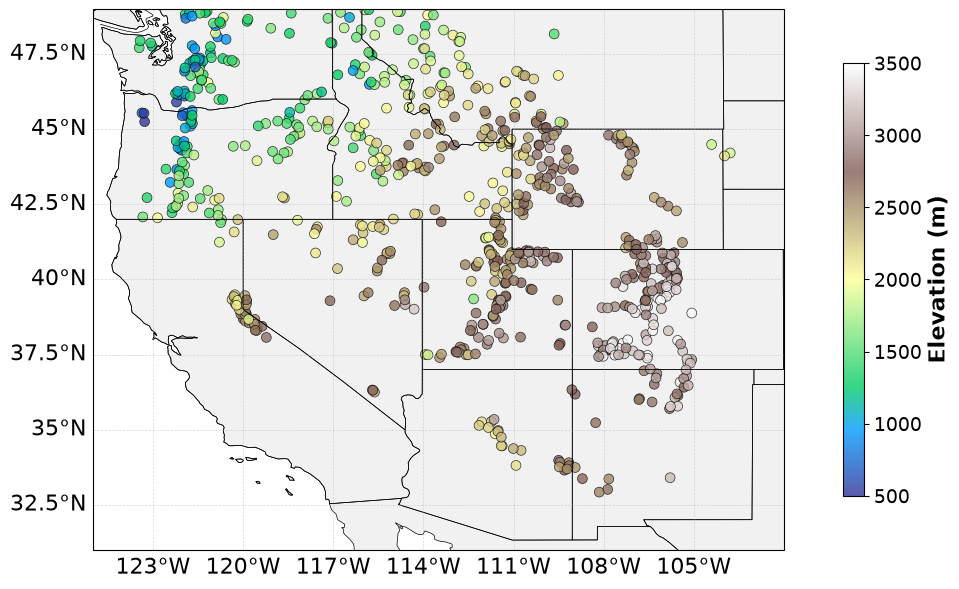

In [12]:
# Single map plot
map_type = 'Elevation'
map_configs = {'Elevation':'ELEVATION'}
fig = plt.figure(figsize=(12, 6))
ax = plt.subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
scatter = ax.scatter(merged_df['longitude'], merged_df['latitude'],
                     c=merged_df[map_configs[map_type]],
                     s=50,
                     alpha=0.8,
                     cmap='terrain',
                     vmin=500,
                     vmax=3500,
                     transform=ccrs.PlateCarree(),
                     edgecolors='black',
                     linewidth=0.5)
cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
cbar.set_label('Elevation (m)', fontsize=16, fontweight='bold')
cbar.ax.tick_params(labelsize=14)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.geo_labels = False
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
plt.tight_layout()
fig.savefig('../images/ElevationMap.pdf', bbox_inches='tight')

#### Bias and Elevation

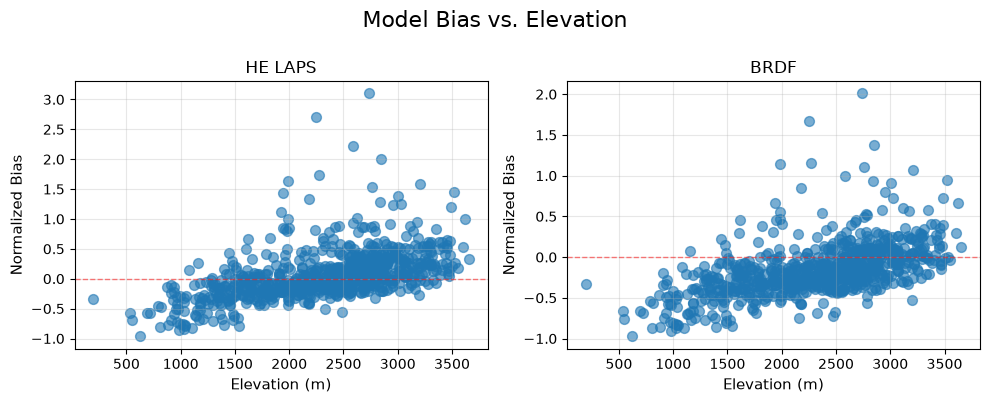

Number of sites plotted: 765


In [13]:
# Bias and Elevation
# Create 2x2 subplot figure
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle('Model Bias vs. Elevation', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']

# Define titles for each subplot
titles = ['HE LAPS', 'BRDF']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    ax = axes[idx]
    
    # Create scatter plot
    ax.scatter(merged_df['ELEVATION'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Elevation (m)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Number of sites plotted: {len(merged_df)}")

In [ ]:
# Compare to NLDAS elevation
# Load the NLDAS elevation netcdf file
import xarray as xr
NLDAS_PATH = 'C:/Users/clmbn/NMT_PhD/data/nldas/'
nldas_elevation = xr.open_dataset(os.path.join(NLDAS_PATH,'NLDAS_elevation.nc4'))
#nldas_elevation = xr.open_dataset('/home/chriscox/Data/nldas/NLDAS_elevation.nc4')
nldas_elevation

In [ ]:
# Extract elevations from the NLDAS dataset using latitude and longitude from cm_data
lats = merged_df['latitude'].values
lons = merged_df['longitude'].values

elevations = nldas_elevation.sel(
    lat=xr.DataArray(lats, dims="points"),
    lon=xr.DataArray(lons, dims="points"),
    method="nearest"
)["NLDAS_elev"].values[0]

elevations

In [ ]:
merged_df['nldas_elevation'] = elevations

KeyError: 'nldas_elevation'

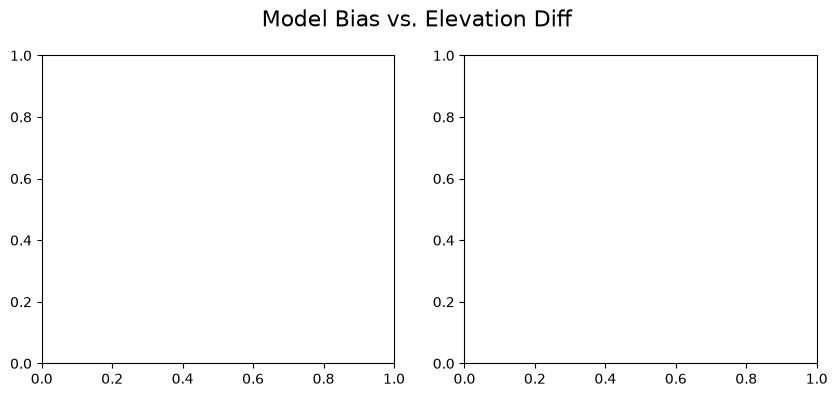

In [14]:
# Bias and Elevation Difference with NLDAS
# Create 2x2 subplot figure
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle('Model Bias vs. Elevation Diff', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']

# Define titles for each subplot
titles = ['HE LAPS', 'BRDF']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    ax = axes[idx]
    
    # Create scatter plot
    ax.scatter(merged_df['nldas_elevation'] - merged_df['ELEVATION'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Elevation (m)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

Raw NLDAS

In [ ]:
# Bias and Elevation Difference with NLDAS
# Create 2x2 subplot figure
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle('Model Bias vs. Elevation Diff', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghelaps']

# Define titles for each subplot
titles = ['Baseline', 'HE-LAPS']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    ax = axes[idx]
    
    # Create scatter plot
    ax.scatter(merged_df['nldas_elevation'] - merged_df['ELEVATION'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Elevation (m)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

### Bias and Other Topography

In [ ]:
# Create 2x2 subplot figure for SKY_VIEW_FACTOR
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
fig.suptitle('Model Bias vs. Sky View Factor', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc',
                'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)',
          'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Create scatter plot
    ax.scatter(merged_df['SKY_VIEW_FACTOR'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Sky View Factor', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Create 2x2 subplot figure for Eastness (sin of aspect)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Model Bias vs. Eastness (sin of Aspect)', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Create scatter plot
    ax.scatter(merged_df['eastness'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Eastness (-1=West, +1=East)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)
    # Add a vertical line at x=0 to separate east/west facing
    ax.axvline(x=0, color='gray', linestyle=':', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Create 2x2 subplot figure for Northness (cos of aspect)
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Model Bias vs. Northness (cos of Aspect)', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Create scatter plot
    ax.scatter(merged_df['northness'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Northness (-1=South, +1=North)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)
    # Add a vertical line at x=0 to separate north/south facing
    ax.axvline(x=0, color='gray', linestyle=':', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Create 2x2 subplot figure for Std Topo
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
fig.suptitle('Model Bias vs. Sigma Elev', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc',
                'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)',
          'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Create scatter plot
    ax.scatter(merged_df['STDEV_ELEV'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('STD Elev (m)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Create 2x2 subplot figure for SLOPE
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Model Bias vs. Slope', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Create scatter plot
    ax.scatter(merged_df['SLOPE'], merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('Slope (degrees)', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Binned Aspect Analysis
# Bin stations into cardinal directions (N, S, E, W) based on aspect ± 45°
def categorize_aspect(aspect_degrees):
    """
    Categorize aspect into cardinal directions:
    - North (N): 315° to 45° (0° ± 45°)
    - East (E): 45° to 135° (90° ± 45°)
    - South (S): 135° to 225° (180° ± 45°)
    - West (W): 225° to 315° (270° ± 45°)
    """
    if (aspect_degrees >= 315) or (aspect_degrees < 45):
        return 'North'
    elif 45 <= aspect_degrees < 135:
        return 'East'
    elif 135 <= aspect_degrees < 225:
        return 'South'
    elif 225 <= aspect_degrees < 315:
        return 'West'
    else:
        return 'Unknown'

# Apply categorization
merged_df['aspect_category'] = merged_df['ASPECT'].apply(categorize_aspect)

# Create 2x2 subplot figure for aspect categories
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
fig.suptitle('Model Bias by Aspect (Cardinal Directions)', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc',
                'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)',
          'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']

# Order of categories for consistent plotting
aspect_categories = ['North', 'East', 'South', 'West']

# Create violin plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Prepare data for violin plot
    data_to_plot = [merged_df[merged_df['aspect_category'] == cat][bias_col].dropna().values 
                    for cat in aspect_categories]
    
    # Create violin plot
    parts = ax.violinplot(data_to_plot, positions=range(len(aspect_categories)), 
                          showmeans=True, showmedians=False, widths=0.7)
    
    # Customize violin colors (blue for N, yellow for E, red for S, orange for W)
    colors = ['lightblue', 'gold', 'lightcoral', 'orange']
    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.6)
        pc.set_edgecolor('black')
        pc.set_linewidth(1)
    
    # Customize mean markers (make them more visible)
    parts['cmeans'].set_edgecolor('red')
    parts['cmeans'].set_linewidth(3)
    
    # Customize other elements
    for partname in ('cbars', 'cmins', 'cmaxes'):
        parts[partname].set_edgecolor('black')
        parts[partname].set_linewidth(1)
    
    # Overlay individual data points
    for i, category in enumerate(aspect_categories):
        category_data = merged_df[merged_df['aspect_category'] == category][bias_col].dropna()
        x_positions = np.random.normal(i, 0.04, size=len(category_data))
        ax.scatter(x_positions, category_data, alpha=0.4, s=20, color='black', zorder=3)
    
    # Add labels and title
    ax.set_xticks(range(len(aspect_categories)))
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3, axis='y')
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.5)
    
    # Add sample sizes to x-axis labels
    category_counts = merged_df.groupby('aspect_category')[bias_col].count()
    new_labels = [f"{cat}\n(n={category_counts.get(cat, 0)})" 
                  for cat in aspect_categories]
    ax.set_xticklabels(new_labels, rotation=0, ha='center', fontsize=10)

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nSummary by aspect category:")
print("=" * 60)
for category in aspect_categories:
    cat_data = merged_df[merged_df['aspect_category'] == category]
    print(f"\n{category} (n={len(cat_data)}):")
    aspect_range = cat_data['ASPECT'].agg(['min', 'max', 'mean'])
    print(f"  Aspect range: {aspect_range['min']:.1f}° to {aspect_range['max']:.1f}° (mean: {aspect_range['mean']:.1f}°)")
    for bias_col in bias_columns:
        mean_bias = cat_data[bias_col].mean()
        std_bias = cat_data[bias_col].std()
        print(f"  {bias_col}: {mean_bias:.3f} ± {std_bias:.3f}")

### Vegetation

In [ ]:
# Load vegetation data
snotel_veg = pd.read_csv(SNOTEL_PATH + 'snotel_veg.csv')

# Merge bias_df with snotel_veg on site name
# Need to match 'site' in bias_df with 'SNOTEL Name' in snotel_veg
veg_merged_df = bias_df.merge(snotel_veg[['SNOTEL Name', 'PFT_INDEX']], 
                               left_on='site', right_on='SNOTEL Name', how='inner')

In [ ]:
# Create 2x2 subplot figure for PFT_INDEX
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
fig.suptitle('Model Bias vs. Plant Functional Type Index', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc',
                'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)',
          'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']

# Create scatter plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Create scatter plot
    ax.scatter(veg_merged_df['PFT_INDEX'], veg_merged_df[bias_col], alpha=0.6, s=50)
    
    # Add labels and title
    ax.set_xlabel('PFT Index', fontsize=11)
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='r', linestyle='--', linewidth=1, alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Number of sites with vegetation data: {len(veg_merged_df)}")
print(f"Total sites in bias_df: {len(bias_df)}")
print(f"Total sites in snotel_veg: {len(snotel_veg)}")

In [ ]:
# Create categorical groupings for PFT_INDEX
def categorize_pft(pft_index):
    """
    Categorize PFT_INDEX into broader groups:
    - soil: 0
    - grass: 12, 13, 14
    - evergreen trees: 1, 2, 4, 5 (needleleaf and broadleaf evergreen)
    - broadleaf deciduous: 6, 7, 8 (broadleaf deciduous trees)
    """
    if pft_index == 0:
        return 'Soil'
    elif pft_index in [12, 13, 14]:
        return 'Grass'
    elif pft_index in [1, 2, 4, 5]:
        return 'Evergreen Trees'
    elif pft_index in [6, 7, 8]:
        return 'Broadleaf Deciduous'
    else:
        return 'Other'

# Apply categorization
veg_merged_df['vegetation_category'] = veg_merged_df['PFT_INDEX'].apply(categorize_pft)

# Filter to only the 4 main categories
main_categories = ['Soil', 'Grass', 'Evergreen Trees', 'Broadleaf Deciduous']
veg_filtered = veg_merged_df[veg_merged_df['vegetation_category'].isin(main_categories)]

# Create 2x2 subplot figure for vegetation categories
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
fig.suptitle('Model Bias by Vegetation Type', fontsize=16, y=0.995)

# Define the bias columns to plot
bias_columns = ['nbias_s00000000_ghec', 'nbias_s01011010_ghec', 
                'nbias_s01011010_ghelaps', 'nbias_s01011010_gbc',
                'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']

# Define titles for each subplot
titles = ['Baseline (s00000000_ghec)', 'HE Clean (s01011010_ghec)',
          'HE LAPS (s01011010_ghelaps)', 'BRDF (s01011010_gbc)',
          'nbias_s01011010_ghelaps_veg', 'nbias_s01012010_ghelaps']

# Create violin plots
for idx, (bias_col, title) in enumerate(zip(bias_columns, titles)):
    row = idx // 2
    col = idx % 2
    ax = axes[row, col]
    
    # Prepare data for violin plot
    data_to_plot = [veg_filtered[veg_filtered['vegetation_category'] == cat][bias_col].values 
                    for cat in main_categories]
    
    # Create violin plot
    parts = ax.violinplot(data_to_plot, positions=range(len(main_categories)), 
                          showmeans=True, showmedians=False, widths=0.7)
    
    # Customize violin colors
    colors = ['brown', 'green', 'darkgreen', 'orange']
    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.6)
        pc.set_edgecolor('black')
        pc.set_linewidth(1)
    
    # Customize mean markers (make them more visible)
    parts['cmeans'].set_edgecolor('red')
    parts['cmeans'].set_linewidth(3)
    
    # Customize other elements
    for partname in ('cbars', 'cmins', 'cmaxes'):
        parts[partname].set_edgecolor('black')
        parts[partname].set_linewidth(1)
    
    # Overlay individual data points
    for i, category in enumerate(main_categories):
        category_data = veg_filtered[veg_filtered['vegetation_category'] == category][bias_col]
        x_positions = np.random.normal(i, 0.04, size=len(category_data))
        ax.scatter(x_positions, category_data, alpha=0.4, s=20, color='black', zorder=3)
    
    # Add labels and title
    ax.set_xticks(range(len(main_categories)))
    ax.set_ylabel('Normalized Bias', fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.grid(True, alpha=0.3, axis='y')
    
    # Add a horizontal line at y=0 for reference
    ax.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.5)
    
    # Add sample sizes to x-axis labels
    category_stats = veg_filtered.groupby('vegetation_category')[bias_col].agg(['count'])
    category_stats = category_stats.reindex(main_categories)
    new_labels = [f"{cat}\n(n={int(category_stats.loc[cat, 'count'])})" 
                  for cat in main_categories]
    ax.set_xticklabels(new_labels, rotation=45, ha='right', fontsize=9)

plt.tight_layout()
plt.show()

# Print summary statistics
print("\nSummary by vegetation category:")
print("=" * 60)
for category in main_categories:
    cat_data = veg_filtered[veg_filtered['vegetation_category'] == category]
    print(f"\n{category} (n={len(cat_data)}):")
    print(f"  PFT indices: {sorted(cat_data['PFT_INDEX'].unique())}")
    for bias_col in bias_columns:
        mean_bias = cat_data[bias_col].mean()
        std_bias = cat_data[bias_col].std()
        print(f"  {bias_col}: {mean_bias:.3f} ± {std_bias:.3f}")

# Show what was excluded
other_count = len(veg_merged_df[veg_merged_df['vegetation_category'] == 'Other'])
if other_count > 0:
    print(f"\n'Other' category (excluded from plot, n={other_count}):")
    other_pft = veg_merged_df[veg_merged_df['vegetation_category'] == 'Other']['PFT_INDEX'].unique()
    print(f"  PFT indices: {sorted(other_pft)}")

In [ ]:
# HE-LAPS focused
# Combine aspect and vegetation data for HE-LAPS model only
# First, merge aspect categories into the vegetation dataframe
veg_aspect_df = veg_merged_df.merge(merged_df[['site', 'aspect_category']], 
                                      on='site', how='inner')

# Apply vegetation categorization to this merged dataframe
veg_aspect_df['vegetation_category'] = veg_aspect_df['PFT_INDEX'].apply(categorize_pft)

# Filter to only the 4 main vegetation categories
veg_aspect_filtered = veg_aspect_df[veg_aspect_df['vegetation_category'].isin(main_categories)]

# Create 1x2 subplot figure for HE-LAPS only
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('HE-LAPS Model Bias by Aspect and Vegetation', fontsize=16, y=0.995)

bias_col = 'nbias_s01011010_ghelaps'  # HE-LAPS only

# Left plot: Aspect
ax = axes[0]
aspect_categories = ['North', 'East', 'South', 'West']

# Prepare data for violin plot
data_to_plot = [veg_aspect_filtered[veg_aspect_filtered['aspect_category'] == cat][bias_col].dropna().values 
                for cat in aspect_categories]

# Create violin plot
parts = ax.violinplot(data_to_plot, positions=range(len(aspect_categories)), 
                      showmeans=True, showmedians=False, widths=0.7)

# Customize violin colors (blue for N, yellow for E, red for S, orange for W)
colors = ['lightblue', 'gold', 'lightcoral', 'orange']
for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(colors[i])
    pc.set_alpha(0.6)
    pc.set_edgecolor('black')
    pc.set_linewidth(1)

# Customize mean markers
parts['cmeans'].set_edgecolor('red')
parts['cmeans'].set_linewidth(3)

# Customize other elements
for partname in ('cbars', 'cmins', 'cmaxes'):
    parts[partname].set_edgecolor('black')
    parts[partname].set_linewidth(1)

# Overlay individual data points
for i, category in enumerate(aspect_categories):
    category_data = veg_aspect_filtered[veg_aspect_filtered['aspect_category'] == category][bias_col].dropna()
    x_positions = np.random.normal(i, 0.04, size=len(category_data))
    ax.scatter(x_positions, category_data, alpha=0.4, s=20, color='black', zorder=3)

# Add labels and title
ax.set_xticks(range(len(aspect_categories)))
ax.set_ylabel('Normalized Bias', fontsize=12)
ax.set_title('By Aspect', fontsize=13)
ax.grid(True, alpha=0.3, axis='y')
ax.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.5)

# Add sample sizes to x-axis labels
category_counts = veg_aspect_filtered.groupby('aspect_category')[bias_col].count()
new_labels = [f"{cat}\n(n={category_counts.get(cat, 0)})" 
              for cat in aspect_categories]
ax.set_xticklabels(new_labels, rotation=0, ha='center', fontsize=10)

# Right plot: Vegetation
ax = axes[1]

# Prepare data for violin plot
data_to_plot = [veg_aspect_filtered[veg_aspect_filtered['vegetation_category'] == cat][bias_col].values 
                for cat in main_categories]

# Create violin plot
parts = ax.violinplot(data_to_plot, positions=range(len(main_categories)), 
                      showmeans=True, showmedians=False, widths=0.7)

# Customize violin colors
veg_colors = ['brown', 'green', 'darkgreen', 'orange']
for i, pc in enumerate(parts['bodies']):
    pc.set_facecolor(veg_colors[i])
    pc.set_alpha(0.6)
    pc.set_edgecolor('black')
    pc.set_linewidth(1)

# Customize mean markers
parts['cmeans'].set_edgecolor('red')
parts['cmeans'].set_linewidth(3)

# Customize other elements
for partname in ('cbars', 'cmins', 'cmaxes'):
    parts[partname].set_edgecolor('black')
    parts[partname].set_linewidth(1)

# Overlay individual data points
for i, category in enumerate(main_categories):
    category_data = veg_aspect_filtered[veg_aspect_filtered['vegetation_category'] == category][bias_col]
    x_positions = np.random.normal(i, 0.04, size=len(category_data))
    ax.scatter(x_positions, category_data, alpha=0.4, s=20, color='black', zorder=3)

# Add labels and title
ax.set_xticks(range(len(main_categories)))
ax.set_ylabel('Normalized Bias', fontsize=12)
ax.set_title('By Vegetation Type', fontsize=13)
ax.grid(True, alpha=0.3, axis='y')
ax.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.5)

# Add sample sizes to x-axis labels
category_stats = veg_aspect_filtered.groupby('vegetation_category')[bias_col].agg(['count'])
category_stats = category_stats.reindex(main_categories)
new_labels = [f"{cat}\n(n={int(category_stats.loc[cat, 'count'])})" 
              for cat in main_categories]
ax.set_xticklabels(new_labels, rotation=45, ha='right', fontsize=9)

plt.tight_layout()
plt.show()

# Print summary statistics for HE-LAPS model
print("\nHE-LAPS Model Summary:")
print("=" * 60)
print("\nBy Aspect:")
for category in aspect_categories:
    cat_data = veg_aspect_filtered[veg_aspect_filtered['aspect_category'] == category]
    mean_bias = cat_data[bias_col].mean()
    std_bias = cat_data[bias_col].std()
    print(f"  {category} (n={len(cat_data)}): {mean_bias:.3f} ± {std_bias:.3f}")

print("\nBy Vegetation:")
for category in main_categories:
    cat_data = veg_aspect_filtered[veg_aspect_filtered['vegetation_category'] == category]
    mean_bias = cat_data[bias_col].mean()
    std_bias = cat_data[bias_col].std()
    print(f"  {category} (n={len(cat_data)}): {mean_bias:.3f} ± {std_bias:.3f}")